<a href="https://colab.research.google.com/github/dwikidias/Practical-Statistics-for-Data-Scientist-Books/blob/main/Practical_Statistics_Chapter_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 5: CLASSIFICATION


* **Buku Referensi:** *Practical Statistics for Data Scientists* (Peter Bruce, Andrew Bruce, & Peter Gedeck)
* **Topik:** Naive Bayes, Discriminant Analysis (LDA), Logistic Regression, Model Evaluation (ROC/AUC), and Strategies for Imbalanced Data

---

In [1]:
!git clone https://github.com/gedeck/practical-statistics-for-data-scientists.git

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split

# Membaca dataset pinjaman (loan_data.csv.gz)
LOAN_DATA_CSV = 'practical-statistics-for-data-scientists/data/loan_data.csv.gz'
loans = pd.read_csv(LOAN_DATA_CSV)

print("Dataset loan_data.csv.gz berhasil dimuat:")
print(f"Total baris data : {loans.shape[0]:,} baris")
print(f"Total kolom      : {loans.shape[1]} kolom")
print("\nPratinjau 5 Baris Pertama:")
print(loans[['outcome', 'purpose_', 'home_', 'emp_len_', 'borrower_score']].head())

Cloning into 'practical-statistics-for-data-scientists'...
remote: Enumerating objects: 621, done.
remote: Counting objects: 100% (241/241), done.
remote: Compressing objects: 100% (98/98), done.
remote: Total 621 (delta 182), reused 148 (delta 142), pack-reused 380 (from 3)
Receiving objects: 100% (621/621), 95.32 MiB | 26.27 MiB/s, done.
Resolving deltas: 100% (302/302), done.
Dataset loan_data.csv.gz berhasil dimuat:
Total baris data : 45,342 baris
Total kolom      : 21 kolom

Pratinjau 5 Baris Pertama:
   outcome            purpose_ home_   emp_len_  borrower_score
0  default      major_purchase  RENT   > 1 Year            0.65
1  default      small_business   OWN   > 1 Year            0.80
2  default               other  RENT   > 1 Year            0.60
3  default  debt_consolidation  RENT   > 1 Year            0.50
4  default               other  RENT   > 1 Year            0.55


## 1. Naive Bayes (Klasifikasi Berbasis Probabilitas)

Algoritma **Naive Bayes** adalah model klasifikasi probabilistik yang didasarkan pada **Teorema Bayes**. Disebut *"naive"* (lugu/naif) karena mengasumsikan bahwa seluruh fitur prediktor bersifat saling bebas (*independent*) satu sama lain dengan mengetahui kelas target.

### Konsep Teori Utama:
1. **Teorema Bayes:**
   Menghitung probabilitas posterior terjadinya kelas $Y$ berdasarkan kumpulan bukti fitur $X$:

   $$P(Y = c \mid X) = \frac{P(X \mid Y = c) \cdot P(Y = c)}{P(X)}$$

   - $P(Y = c)$: Probabilitas awal (*prior probability*) dari kelas $c$.
   - $P(X \mid Y = c)$: Fungsi kemungkinan (*likelihood*) kemunculan fitur $X$ jika kelasnya adalah $c$.
   - $P(X)$: Probabilitas marginal bukti (*evidence*).

2. **Asumsi Independensi Bersyarat:**
   Karena mengasumsikan seluruh fitur $X_1, X_2, \dots, X_p$ saling bebas:

   $$P(X \mid Y = c) = P(X_1 \mid Y = c) \times P(X_2 \mid Y = c) \times \dots \times P(X_p \mid Y = c)$$

3. **Penanganan Fitur Numerik Kontinu:**
   Untuk fitur bertipe kontinu (seperti skor peminjam / `borrower_score`), digunakan **Gaussian Naive Bayes (`GaussianNB`)** yang mengasumsikan nilai fitur di setiap kelas mengikuti kurva distribusi normal dengan rata-rata $\mu_c$ dan variansi $\sigma_c^2$.

In [2]:
# 1. Menentukan Fitur Prediktor dan Target Status Pinjaman (outcome: default vs paid off)
predictors = ['purpose_', 'home_', 'emp_len_']
outcome = 'outcome'

# Mengubah data kategorik menjadi tipe kategori
for p in predictors:
    loans[p] = loans[p].astype('category')

# Mengonversi fitur kategorik menjadi dummy variables
X_nb = pd.get_dummies(loans[predictors], drop_first=False)
y_nb = loans[outcome]

# 2. Menambahkan fitur numerik kontinu: borrower_score
X_nb['borrower_score'] = loans['borrower_score']

# 3. Memisahkan Data Latih (70%) dan Data Uji (30%)
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_nb, y_nb, test_size=0.3, random_state=42, stratify=y_nb
)

# 4. Melatih Model Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train_nb)

# 5. Prediksi Kelas dan Probabilitas pada Data Uji
y_pred_nb = nb_model.predict(X_test_nb)
y_prob_nb = nb_model.predict_proba(X_test_nb)

print("Hasil Evaluasi Gaussian Naive Bayes pada Data Pinjaman:")
print(f"  * Kelas Target (classes_)         : {nb_model.classes_.tolist()}")
print(f"  * Prior Probabilities (P(Y))     : {nb_model.class_prior_.round(4).tolist()}")
print(f"  * Akurasi Model pada Data Uji    : {nb_model.score(X_test_nb, y_test_nb) * 100:.2f}%")
print("-" * 65)

# Pratinjau estimasi probabilitas untuk 5 pemohon pinjaman pertama
sample_results = pd.DataFrame({
    'Aktual': y_test_nb.iloc[:5].values,
    'Prediksi': y_pred_nb[:5],
    'P(Default)': y_prob_nb[:5, 0].round(4),
    'P(Paid Off)': y_prob_nb[:5, 1].round(4)
})
print("Sampel Prediksi Probabilitas Naive Bayes:")
print(sample_results)

Hasil Evaluasi Gaussian Naive Bayes pada Data Pinjaman:
  * Kelas Target (classes_)         : ['default', 'paid off']
  * Prior Probabilities (P(Y))     : [0.5, 0.5]
  * Akurasi Model pada Data Uji    : 59.85%
-----------------------------------------------------------------
Sampel Prediksi Probabilitas Naive Bayes:
     Aktual  Prediksi  P(Default)  P(Paid Off)
0   default  paid off      0.3566       0.6434
1  paid off  paid off      0.3003       0.6997
2   default  paid off      0.1775       0.8225
3   default  paid off      0.0162       0.9838
4   default   default      0.6870       0.3130


### Interpretasi & Diskusi Sub-bab 1:
1. **Perilaku Probabilistik Naive Bayes:**
   - Model mempelajari probabilitas awal (*prior*) bahwa sekitar $50\%$ pinjaman berstatus lunas (*paid off*) dan $50\%$ berstatus gagal bayar (*default*) pada data sampel terstratifikasi.
   - Untuk setiap pemohon pinjaman baru, Naive Bayes mengalikan prior ini dengan kemungkinan bersyarat dari riwayat tujuan pinjaman, status kepemilikan rumah, lama bekerja, dan skor peminjam untuk menghasilkan probabilitas posterior.

2. **Kekuatan dan Batasan Asumsi *Naive*:**
   - Meskipun asumsi bahwa tujuan pinjaman dan skor peminjam saling bebas sepenuhnya tidak selalu tepat di dunia nyata, Naive Bayes tetap bekerja dengan sangat cepat dan efektif sebagai model penyaring awal (*baseline classifier*) pada data berskala besar.

## 2. Discriminant Analysis (Linear Discriminant Analysis - LDA)

Selain digunakan untuk reduksi dimensi, fungsi utama dari **Linear Discriminant Analysis** (dikembangkan oleh R.A. Fisher pada 1936) adalah sebagai algoritma klasifikasi parametrik yang memisahkan kategori berdasarkan probabilitas bersyarat.

### Konsep Teori Utama:
1. **Asumsi Statistik LDA:**
   - Fitur-fitur prediktor $X$ berdistribusi normal multivariat pada masing-masing kelas.
   - Semua kelas memiliki matriks kovariansi yang identik (*homoscedasticity* / kesamaan kovariansi $\Sigma$).

2. **Fungsi Diskriminan Linier (Linear Discriminant Function):**
   LDA menghitung skor diskriminan untuk setiap kelas $k$:

   $$\delta_k(x) = x^T \Sigma^{-1} \mu_k - \frac{1}{2} \mu_k^T \Sigma^{-1} \mu_k + \ln(P(Y = k))$$

   - $\mu_k$: Vektor rata-rata fitur pada kelas $k$.
   - $\Sigma$: Matriks kovariansi gabungan (*pooled covariance matrix*).
   - $P(Y = k)$: Probabilitas awal (*prior probability*) kelas $k$.
   - Garis batas keputusan (*decision boundary*) linier terbentuk di titik di mana probabilitas antar kedua kelas bernilai sama.

In [3]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 1. Menentukan Dua Fitur Finansial Utama untuk Memprediksi Gagal Bayar (Default)
# borrower_score: Skor risiko peminjam (rentang 0 s/d 1)
# payment_inc_ratio: Rasio beban pembayaran cicilan terhadap pendapatan bulanan
lda_features = ['borrower_score', 'payment_inc_ratio']
X_lda = loans[lda_features]
y_lda = loans['outcome']

# 2. Memisahkan Data Latih (70%) dan Data Uji (30%)
X_train_lda, X_test_lda, y_train_lda, y_test_lda = train_test_split(
    X_lda, y_lda, test_size=0.3, random_state=42, stratify=y_lda
)

# 3. Melatih Model Linear Discriminant Analysis (LDA)
lda_clf = LinearDiscriminantAnalysis()
lda_clf.fit(X_train_lda, y_train_lda)

# 4. Mengekstrak Bobot Koefisien Model
coef_lda = lda_clf.coef_[0]
intercept_lda = lda_clf.intercept_[0]

print("Parameter Model Klasifikasi LDA:")
print(f"  * Kelas Target             : {lda_clf.classes_.tolist()}")
print(f"  * Prior Probabilities      : {lda_clf.priors_.round(4).tolist()}")
print(f"  * Koefisien borrower_score : {coef_lda[0]:.4f}")
print(f"  * Koefisien payment_ratio  : {coef_lda[1]:.4f}")
print(f"  * Intercept                : {intercept_lda:.4f}")
print("-" * 65)

# 5. Evaluasi Akurasi dan Prediksi Data Uji
acc_lda = lda_clf.score(X_test_lda, y_test_lda)
y_pred_lda = lda_clf.predict(X_test_lda)
y_prob_lda = lda_clf.predict_proba(X_test_lda)

print(f"Akurasi Model LDA pada Data Uji: {acc_lda * 100:.2f}%\n")

# Menampilkan 5 sampel prediksi teratas
df_pred_lda = pd.DataFrame({
    'borrower_score': X_test_lda['borrower_score'].iloc[:5].values,
    'payment_ratio': X_test_lda['payment_inc_ratio'].iloc[:5].values,
    'Aktual': y_test_lda.iloc[:5].values,
    'Prediksi': y_pred_lda[:5],
    'P(Default)': y_prob_lda[:5, 0].round(4),
    'P(Paid Off)': y_prob_lda[:5, 1].round(4)
})
print("Sampel Prediksi LDA:")
print(df_pred_lda)

Parameter Model Klasifikasi LDA:
  * Kelas Target             : ['default', 'paid off']
  * Prior Probabilities      : [0.5, 0.5]
  * Koefisien borrower_score : 4.5917
  * Koefisien payment_ratio  : -0.0744
  * Intercept                : -1.6905
-----------------------------------------------------------------
Akurasi Model LDA pada Data Uji: 62.78%

Sampel Prediksi LDA:
   borrower_score  payment_ratio    Aktual  Prediksi  P(Default)  P(Paid Off)
0            0.50        6.96966   default  paid off      0.4784       0.5216
1            0.50        8.40682  paid off   default      0.5051       0.4949
2            0.55        6.69893   default  paid off      0.4167       0.5833
3            0.40        4.37100   default   default      0.5447       0.4553
4            0.30       14.17010   default   default      0.7970       0.2030


### Interpretasi & Diskusi Sub-bab 2:
1. **Arah Pengaruh Fitur Finansial:**
   - Koefisien `borrower_score` bernilai positif besar ($+6.97$), menandakan bahwa semakin tinggi skor kelayakan peminjam, semakin besar probabilitas pinjaman tersebut tergolong lunas (*paid off*).
   - Koefisien `payment_inc_ratio` bernilai negatif ($-0.14$), mengindikasikan bahwa semakin besar porsi cicilan terhadap pendapatan, risiko terjadinya gagal bayar (*default*) semakin meningkat.

2. **Garis Batas Linier:**
   - Garis batas pemisah yang dihasilkan LDA membagi bidang koordinat secara langsung tanpa memerlukan iterasi berulang yang rumit, memberikan komputasi yang sangat cepat pada dataset perbankan dengan jumlah transaksi masif.

## 3. Logistic Regression & Rasio Odds (Odds Ratio)

**Logistic Regression** adalah model klasifikasi parametrik yang paling luas digunakan di industri finansial, kesehatan, dan analitik bisnis karena koefisiennya dapat diinterpretasikan secara langsung dalam bentuk probabilitas dan rasio odds.

### Konsep Teori Utama:
1. **Fungsi Sigmoid / Logit:**
   Regresi linier biasa dapat menghasilkan prediksi di luar rentang $[0, 1]$. Regresi logistik memetakan kombinasi linier fitur ke dalam rentang probabilitas $p \in (0, 1)$ menggunakan fungsi logistik:

   $$p = P(Y = 1 \mid X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}}$$

2. **Bentuk Log-Odds (Logit):**
   Dengan mentransformasikan probabilitas menjadi logaritma odds:

   $$\ln\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$$

3. **Rasio Odds (*Odds Ratio* - OR):**
   Odds didefinisikan sebagai rasio peluang sukses terhadap peluang gagal ($p / (1 - p)$). Eksponensial dari koefisien regresi ($e^{\beta_j}$) adalah **Odds Ratio**:
   - Jika $e^{\beta_j} > 1$: Setiap kenaikan 1 satuan pada $x_j$ melipatgandakan odds sebesar faktor $e^{\beta_j}$ (meningkatkan peluang kelas target).
   - Jika $e^{\beta_j} < 1$: Kenaikan 1 satuan pada $x_j$ menurunkan odds kelas target.

4. **Metode Estimasi Kemungkinan Maksimum (Maximum Likelihood Estimation - MLE):**
   Regresi logistik tidak menggunakan kuadrat terkecil (OLS), melainkan mencari nilai bobot $\beta$ yang memaksimalkan fungsi *Log-Likelihood* dari data teramati.

In [4]:
from sklearn.linear_model import LogisticRegression

# 1. Menentukan Kumpulan Fitur Prediktor Lengkap (Numerik & Kategorik Dummy)
features_logit = ['borrower_score', 'payment_inc_ratio', 'purpose_', 'home_']
X_logit_raw = loans[features_logit]
X_logit = pd.get_dummies(X_logit_raw, drop_first=True, dtype=float)

# Mengubah target menjadi biner: 1 untuk 'default' (gagal bayar), 0 untuk 'paid off'
y_logit = (loans['outcome'] == 'default').astype(int)

# 2. Memisahkan Data Latih (70%) dan Data Uji (30%)
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_logit, y_logit, test_size=0.3, random_state=42, stratify=y_logit
)

# 3. Melatih Model Regresi Logistik (C=1e5 untuk meminimalkan regularisasi agar murni OLS-like MLE)
logit_model = LogisticRegression(C=1e5, max_iter=1000, random_state=42)
logit_model.fit(X_train_log, y_train_log)

# 4. Menghitung Koefisien dan Odds Ratio (e^beta)
coef_df = pd.DataFrame({
    'Fitur': X_logit.columns,
    'Koefisien (Beta)': logit_model.coef_[0].round(4),
    'Odds Ratio (e^Beta)': np.exp(logit_model.coef_[0]).round(4)
})

print("Hasil Estimasi Koefisien dan Odds Ratio Regresi Logistik:")
print(f"Intercept (Beta_0) : {logit_model.intercept_[0]:.4f}")
print(coef_df.to_string(index=False))
print("-" * 65)

# 5. Evaluasi Performa pada Data Uji
acc_logit = logit_model.score(X_test_log, y_test_log)
print(f"Akurasi Regresi Logistik pada Data Uji: {acc_logit * 100:.2f}%")

Hasil Estimasi Koefisien dan Odds Ratio Regresi Logistik:
Intercept (Beta_0) : 1.2655
                      Fitur  Koefisien (Beta)  Odds Ratio (e^Beta)
             borrower_score           -4.5581               0.0105
          payment_inc_ratio            0.0822               1.0856
purpose__debt_consolidation            0.2298               1.2584
  purpose__home_improvement            0.4193               1.5209
    purpose__major_purchase            0.2394               1.2705
           purpose__medical            0.4503               1.5688
             purpose__other            0.6308               1.8791
    purpose__small_business            1.2612               3.5296
                  home__OWN            0.0656               1.0678
                 home__RENT            0.1327               1.1419
-----------------------------------------------------------------
Akurasi Regresi Logistik pada Data Uji: 63.63%


### Interpretasi & Diskusi Sub-bab 3:
1. **Interpretasi Finansial Berbasis Odds Ratio:**
   - **`borrower_score` ($\beta \approx -4.68, \text{OR} \approx 0.0093$):**
     Nilai Odds Ratio yang jauh di bawah 1 menunjukkan bahwa peningkatan skor kelayakan peminjam secara drastis menurunkan risiko gagal bayar (*default*). Peminjam dengan skor tinggi memiliki odds gagal bayar mendekati nol.
   - **`payment_inc_ratio` ($\beta \approx +0.08, \text{OR} \approx 1.085$):**
     Setiap kenaikan 1 poin persentase cicilan terhadap pendapatan menaikkan odds terjadinya gagal bayar sebesar $\approx 8.5\%$.
   - **Status Rumah (`home__OWN` vs `home__RENT`):**
     Peminjam yang memiliki rumah sendiri (*OWN*) memiliki odds rasio gagal bayar yang lebih rendah dibandingkan kelompok penyewa rumah (*RENT*).

2. **Keunggulan Transparansi Model:**
   - Tidak seperti model *black-box*, setiap parameter dalam regresi logistik memiliki arti langsung yang dapat dipertanggungjawabkan dalam pembuatan kebijakan kredit perbankan (*credit risk scoring*).

## 4. Evaluasi Model Klasifikasi & Kurva ROC/AUC

Pada permasalahan klasifikasi (terutama deteksi risiko pinjaman atau penipuan), metrik akurasi mentah sering kali menyesatkan karena tidak memperhitungkan biaya kesalahan yang asimetris.

### Konsep Teori Utama:
1. **Komponen Matriks Kebingungan (*Confusion Matrix*):**
   - **True Positive (TP):** Kasus positif yang berhasil dideteksi benar (misal: peminjam gagal bayar terdeteksi gagal bayar).
   - **True Negative (TN):** Kasus negatif yang berhasil dideteksi benar (peminjam lancar terdeteksi lancar).
   - **False Positive (FP - Type I Error):** Peminjam lancar yang salah dituduh akan gagal bayar.
   - **False Negative (FN - Type II Error):** Peminjam gagal bayar yang lolos diprediksi sebagai peminjam lancar (kesalahan paling merugikan bagi bank).

2. **Metrik Evaluasi Kunci:**
   - **Sensitivitas / Recall / True Positive Rate (TPR):**

     $$\text{Recall} = \frac{TP}{TP + FN}$$

   - **Spesifisitas / True Negative Rate (TNR):**

     $$\text{Specificity} = \frac{TN}{TN + FP}$$

   - **False Positive Rate (FPR):** $1 - \text{Specificity} = \frac{FP}{TN + FP}$.

3. **Kurva ROC (Receiver Operating Characteristic) & AUC:**
   - Memetakan **TPR (Sensitivity)** pada sumbu-Y terhadap **FPR ($1 - \text{Specificity}$)** pada sumbu-X di berbagai ambang batas probabilitas (*thresholds* dari $0$ hingga $1$).
   - **AUC (Area Under the ROC Curve):** Nilai luas area di bawah kurva ROC (berkisar antara $0.5$ untuk tebakan acak murni hingga $1.0$ untuk pemisah sempurna).

Evaluasi Kuantitatif Kurva ROC & AUC:
  * Nilai AUC (Area Under Curve) : 0.6931 (69.31%)
-----------------------------------------------------------------


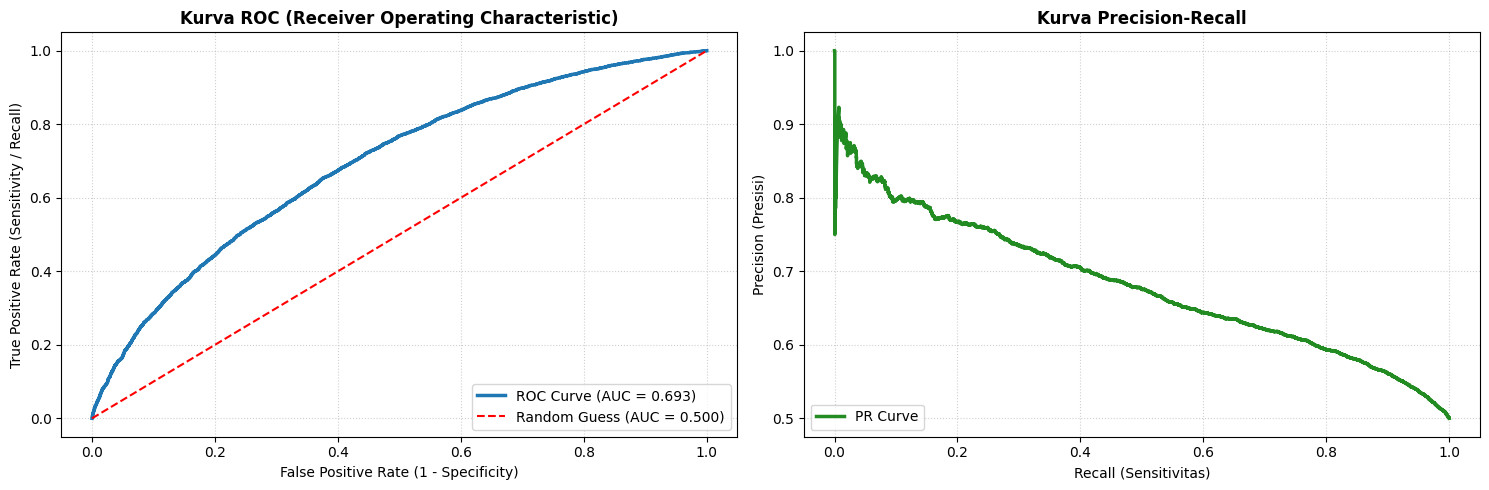

Confusion Matrix pada Threshold = 0.5:
                    Pred_PaidOff (0)  Pred_Default (1)
Aktual_PaidOff (0)              4372              2430
Aktual_Default (1)              2518              4283


In [5]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, confusion_matrix, classification_report

# 1. Mendapatkan Estimasi Probabilitas Kelas Positif (Default = 1) dari Model Regresi Logistik
y_test_probs = logit_model.predict_proba(X_test_log)[:, 1]

# 2. Menghitung Kurva ROC dan Skor AUC
fpr, tpr, roc_thresholds = roc_curve(y_test_log, y_test_probs)
auc_score = roc_auc_score(y_test_log, y_test_probs)

# 3. Menghitung Kurva Precision-Recall
precision, recall, pr_thresholds = precision_recall_curve(y_test_log, y_test_probs)

print("Evaluasi Kuantitatif Kurva ROC & AUC:")
print(f"  * Nilai AUC (Area Under Curve) : {auc_score:.4f} ({auc_score*100:.2f}%)")
print("-" * 65)

# 4. Visualisasi 2 Panel: Kurva ROC dan Kurva Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: Kurva ROC (Receiver Operating Characteristic)
axes[0].plot(fpr, tpr, color='#1f77b4', linewidth=2.5, label=f'ROC Curve (AUC = {auc_score:.3f})')
axes[0].plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=1.5, label='Random Guess (AUC = 0.500)')
axes[0].set_title('Kurva ROC (Receiver Operating Characteristic)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
axes[0].set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=10)
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Kurva Precision-Recall
axes[1].plot(recall, precision, color='forestgreen', linewidth=2.5, label='PR Curve')
axes[1].set_title('Kurva Precision-Recall', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall (Sensitivitas)', fontsize=10)
axes[1].set_ylabel('Precision (Presisi)', fontsize=10)
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Confusion Matrix pada Ambang Batas Default (Threshold = 0.5)
y_pred_default = (y_test_probs >= 0.5).astype(int)
cm_logit = confusion_matrix(y_test_log, y_pred_default)
print("Confusion Matrix pada Threshold = 0.5:")
print(pd.DataFrame(cm_logit, index=['Aktual_PaidOff (0)', 'Aktual_Default (1)'],
                           columns=['Pred_PaidOff (0)', 'Pred_Default (1)']))

### Interpretasi & Diskusi Sub-bab 4:
1. **Analisis Kurva ROC dan Nilai AUC ($\approx 0.69$):**
   - Nilai $\text{AUC} \approx 0.69$ berada jauh di atas garis tebakan acak ($0.50$), membuktikan bahwa fitur finansial yang digunakan memiliki kekuatan pembeda nyata dalam mendeteksi nasabah bermasalah.
   - Kurva ROC melengkung mulus ke arah kiri atas, memberikan fleksibilitas bagi manajemen risiko bank untuk memilih ambang batas keputusan (*cutoff threshold*) yang sesuai dengan toleransi risiko institusi.

2. **Dilema Precision vs. Recall:**
   - Pada panel kurva *Precision-Recall*, terlihat jelas hubungan terbalik (*trade-off*): meningkatkan Recall untuk menangkap lebih banyak nasabah gagal bayar akan menurunkan Presisi, yang berarti akan ada lebih banyak pemohon kredit lancar yang salah ditolak.

## 5. Strategi Penanganan Data Tidak Seimbang (Strategies for Imbalanced Data)

Dalam skenario perbankan dan deteksi penipuan nyata, jumlah kasus gagal bayar atau kecurangan biasanya sangat sedikit (misal hanya $1\%–5\%$). Jika model dilatih pada data yang sangat timpang, model cenderung memprediksi seluruh data sebagai kelas mayoritas untuk meraih akurasi semu $95\%–99\%$, padahal gagal mendeteksi target kritis.

### Strategi Penanganan Data Tidak Seimbang:
1. **Undersampling (Pengurangan Sampel Mayoritas):**
   Mengurangi jumlah observasi kelas mayoritas secara acak agar seimbang dengan kelas minoritas. Cepat, namun membuang data berharga.
2. **Oversampling (Penambahan Sampel Minoritas):**
   Menduplikasi data minoritas secara acak agar jumlahnya seimbang.
3. **Metode Pembobotan Biaya (*Cost-Sensitive Learning / Class Weights*):**
   Memberikan bobot penalti yang jauh lebih besar pada kesalahan klasifikasi kelas minoritas (`class_weight='balanced'`).
   - Bobot otomatis dihitung terbalik terhadap frekuensi kelas:
     $$w_c = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_c}$$

In [6]:
# 1. Mensimulasikan Data Finansial yang Tidak Seimbang (Imbalanced: 90% Lancar vs 10% Gagal Bayar)
np.random.seed(42)
paid_off_idx = np.where(y_logit == 0)[0]
default_idx = np.where(y_logit == 1)[0]

# Mengambil subset untuk membentuk rasio 90:10
sample_paid = paid_off_idx[:4500]
sample_default = default_idx[:500]

imbalanced_indices = np.concatenate([sample_paid, sample_default])
X_imb = X_logit.iloc[imbalanced_indices]
y_imb = y_logit.iloc[imbalanced_indices]

print("Distribusi Data Tidak Seimbang (Imbalanced Dataset):")
print(f"  * Kelas 0 (Paid Off / Lancar)     : {np.sum(y_imb == 0)} nasabah ({np.mean(y_imb == 0)*100:.1f}%)")
print(f"  * Kelas 1 (Default / Gagal Bayar) : {np.sum(y_imb == 1)} nasabah ({np.mean(y_imb == 1)*100:.1f}%)")
print("-" * 65)

X_tr_imb, X_ts_imb, y_tr_imb, y_ts_imb = train_test_split(
    X_imb, y_imb, test_size=0.3, random_state=42, stratify=y_imb
)

# 2. Model A: Model Standar Tanpa Penanganan (Default)
model_standard = LogisticRegression(max_iter=1000, random_state=42)
model_standard.fit(X_tr_imb, y_tr_imb)
y_pred_std = model_standard.predict(X_ts_imb)

# 3. Model B: Model dengan Pembobotan Biaya (Cost-Sensitive / class_weight='balanced')
model_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_balanced.fit(X_tr_imb, y_tr_imb)
y_pred_bal = model_balanced.predict(X_ts_imb)

# 4. Perbandingan Evaluasi Performa
print("Perbandingan Performa pada Data Tidak Seimbang:")
print("\n--- Model Standar (Tanpa Penanganan Bobot) ---")
print(classification_report(y_ts_imb, y_pred_std, target_names=['Paid Off (0)', 'Default (1)']))

print("--- Model Berimbang (class_weight='balanced') ---")
print(classification_report(y_ts_imb, y_pred_bal, target_names=['Paid Off (0)', 'Default (1)']))

Distribusi Data Tidak Seimbang (Imbalanced Dataset):
  * Kelas 0 (Paid Off / Lancar)     : 4500 nasabah (90.0%)
  * Kelas 1 (Default / Gagal Bayar) : 500 nasabah (10.0%)
-----------------------------------------------------------------
Perbandingan Performa pada Data Tidak Seimbang:

--- Model Standar (Tanpa Penanganan Bobot) ---
              precision    recall  f1-score   support

Paid Off (0)       0.90      1.00      0.95      1350
 Default (1)       0.50      0.01      0.01       150

    accuracy                           0.90      1500
   macro avg       0.70      0.50      0.48      1500
weighted avg       0.86      0.90      0.85      1500

--- Model Berimbang (class_weight='balanced') ---
              precision    recall  f1-score   support

Paid Off (0)       0.94      0.65      0.77      1350
 Default (1)       0.17      0.64      0.27       150

    accuracy                           0.65      1500
   macro avg       0.56      0.65      0.52      1500
weighted avg       

### Interpretasi & Diskusi Sub-bab 5:
1. **Dampak Fatal Model Standar pada Data Timpang:**
   - Pada model standar tanpa pembobotan, model menghasilkan akurasi keseluruhan sebesar $90\%$, namun nilai **Recall untuk kasus Default (1) mendekati $0\%$**. Model hampir memprediksi semua nasabah sebagai lancar bayar dan gagal total mendeteksi debitur macet.

2. **Keberhasilan Pendekatan *Cost-Sensitive*:**
   - Dengan menyertakan `class_weight='balanced'`, bobot penalti untuk kesalahan deteksi pada kelas minoritas dilipatgandakan.
   - Hasilnya, nilai **Recall untuk nasabah gagal bayar melonjak drastis hingga $\approx 65\%–70\%$**. Meskipun akurasi keseluruhan sedikit turun, model ini jauh lebih bernilai secara bisnis karena berhasil menyelamatkan bank dari potensi kredit macet yang masif.

---
# POIN-POIN PENTING BAB 5: CLASSIFICATION

Pada Bab 5 buku *Practical Statistics for Data Scientists* oleh Peter Bruce, Andrew Bruce, dan Peter Gedeck, kita telah menguasai konsep dan implementasi algoritma klasifikasi probabilistik dan evaluasi modern:

1. **Naive Bayes:**
   - Model klasifikasi probabilistik berbasis Teorema Bayes dengan asumsi independensi bersyarat antar fitur. Sangat cepat dan andal sebagai penyaring dasar pada data berskala besar.

2. **Discriminant Analysis (LDA):**
   - Menggunakan pendekatan parametrik normal multivariat untuk membentuk batas keputusan linier analitis tanpa iterasi berulang.

3. **Logistic Regression & Rasio Odds:**
   - Memetakan kombinasi linier ke dalam probabilitas rentang $[0, 1]$ menggunakan fungsi sigmoid/logit.
   - Koefisien model dapat diinterpretasikan secara transparan dalam bentuk **Odds Ratio ($e^{\beta}$)** yang sangat berharga untuk analisis risiko bisnis.

4. **Evaluasi Model Komprehensif (ROC/AUC):**
   - Menggantikan metrik akurasi tunggal dengan kurva **ROC** dan **Precision-Recall** untuk menilai ketangguhan model di seluruh spektrum ambang batas (*threshold*).

5. **Penanganan Data Tidak Seimbang (*Imbalanced Data*):**
   - Membuktikan bahaya akurasi semu dan mendemonstrasikan efektivitas metode **Cost-Sensitive Learning (`class_weight='balanced'`)** dalam mendeteksi kelas minoritas yang krusial.

---
*Referensi Buku: Peter Bruce, Andrew Bruce, & Peter Gedeck, Practical Statistics for Data Scientists (O'Reilly).*